step -1 Data Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("crime_train.csv")
df

,Unnamed: 0,Num,case_filed,city,area,crime_description,age,sex,weapon,domain,police_department,closed
0,19794,19795,04-04-2022 18:00,Mumbai,307,VEHICLE - STOLEN,63.0,X,Poison,Violent Crime,12.0,No
1,13762,13763,07-27-2021 10:00,Surat,504,ROBBERY,57.0,F,Explosives,Violent Crime,3.0,No
2,30311,30312,06-16-2023 23:00,Thane,493,ASSAULT,33.0,F,Firearm,Violent Crime,18.0,No
3,5043,5044,07-29-2020 03:00,Ahmedabad,169,PUBLIC INTOXICATION,76.0,F,Knife,Other Crime,3.0,No
4,35008,35009,12-29-2023 16:00,Mumbai,133,PUBLIC INTOXICATION,13.0,M,NaN,Other Crime,13.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...
22484,7639,7640,11-14-2020 07:00,Pune,121,SEXUAL ASSAULT,15.0,M,Explosives,Violent Crime,5.0,No
22485,3658,3659,06-01-2020 10:00,Delhi,112,DOMESTIC VIOLENCE,11.0,F,Other,Violent Crime,2.0,Yes
22486,10653,10654,03-19-2021 21:00,Jaipur,170,FRAUD,38.0,F,Explosives,Other Crime,9.0,Yes
22487,8228,8229,12-08-2020 20:00,Chennai,189,ASSAULT,13.0,F,Knife,Violent Crime,3.0,No


In [3]:
df.shape

(22489, 12)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 22489 entries, 0 to 22488
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         22489 non-null  int64  
 1   Num                22489 non-null  int64  
 2   case_filed         22489 non-null  str    
 3   city               22489 non-null  str    
 4   area               22489 non-null  int64  
 5   crime_description  22489 non-null  str    
 6   age                22489 non-null  float64
 7   sex                22489 non-null  str    
 8   weapon             19217 non-null  str    
 9   domain             22489 non-null  str    
 10  police_department  22489 non-null  float64
 11  closed             22489 non-null  str    
dtypes: float64(2), int64(3), str(7)
memory usage: 3.3 MB


In [5]:
df.isnull().sum()

Unnamed: 0              0
Num                     0
case_filed              0
city                    0
area                    0
crime_description       0
age                     0
sex                     0
weapon               3272
domain                  0
police_department       0
closed                  0
dtype: int64

In [6]:
(df.isnull().sum()/df.shape[0])*100



Unnamed: 0            0.000000
Num                   0.000000
case_filed            0.000000
city                  0.000000
area                  0.000000
crime_description     0.000000
age                   0.000000
sex                   0.000000
weapon               14.549335
domain                0.000000
police_department     0.000000
closed                0.000000
dtype: float64

In [7]:
df.duplicated().sum()

np.int64(0)

Sanity check is finished, next Exploratory data analysis

In [8]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,22489.0,20056.012228,11582.776848,0.0,9991.0,20003.0,30102.0,40159.0
Num,22489.0,20057.012228,11582.776848,1.0,9992.0,20004.0,30103.0,40160.0
area,22489.0,352.043844,144.043406,100.0,229.0,353.0,476.0,599.0
age,22489.0,44.778745,20.614536,4.9,27.0,45.0,62.0,101.9
police_department,22489.0,10.353248,6.846822,-4.1,5.0,10.0,15.0,41.9


In [9]:
df.describe(include='str')

,case_filed,city,crime_description,sex,weapon,domain,closed
count,22489,22489,22489,22489,19217,22489,22489
unique,22489,29,21,3,6,4,2
top,04-04-2022 18:00,Delhi,FRAUD,F,Knife,Other Crime,Yes
freq,1,3011,1131,12541,3283,12888,11253


we dont need unname and Num columns as they are useless to categorize a case is closed or not

In [10]:
df = df.drop(columns = ['Unnamed: 0','Num'])
df

,case_filed,city,area,crime_description,age,sex,weapon,domain,police_department,closed
0,04-04-2022 18:00,Mumbai,307,VEHICLE - STOLEN,63.0,X,Poison,Violent Crime,12.0,No
1,07-27-2021 10:00,Surat,504,ROBBERY,57.0,F,Explosives,Violent Crime,3.0,No
2,06-16-2023 23:00,Thane,493,ASSAULT,33.0,F,Firearm,Violent Crime,18.0,No
3,07-29-2020 03:00,Ahmedabad,169,PUBLIC INTOXICATION,76.0,F,Knife,Other Crime,3.0,No
4,12-29-2023 16:00,Mumbai,133,PUBLIC INTOXICATION,13.0,M,NaN,Other Crime,13.0,No
...,...,...,...,...,...,...,...,...,...,...
22484,11-14-2020 07:00,Pune,121,SEXUAL ASSAULT,15.0,M,Explosives,Violent Crime,5.0,No
22485,06-01-2020 10:00,Delhi,112,DOMESTIC VIOLENCE,11.0,F,Other,Violent Crime,2.0,Yes
22486,03-19-2021 21:00,Jaipur,170,FRAUD,38.0,F,Explosives,Other Crime,9.0,Yes
22487,12-08-2020 20:00,Chennai,189,ASSAULT,13.0,F,Knife,Violent Crime,3.0,No


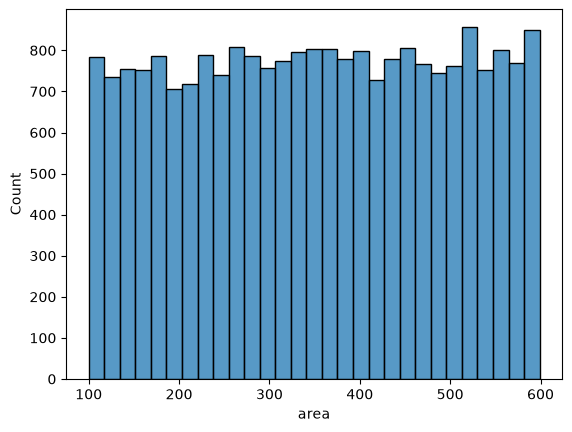

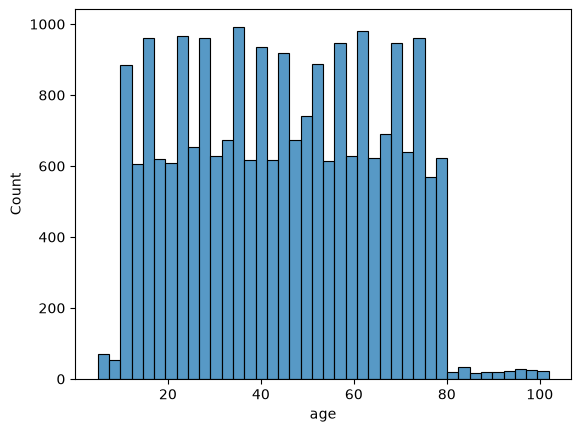

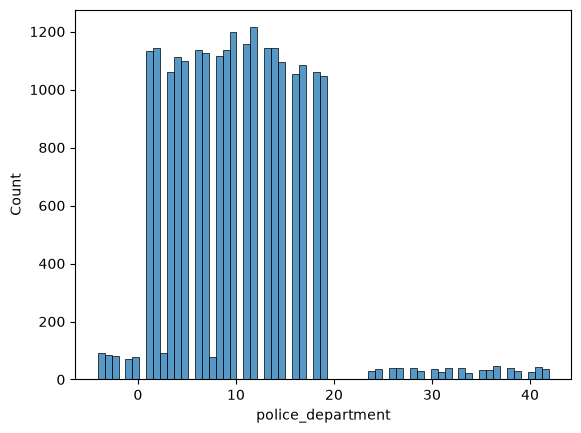

In [11]:
for i in df.select_dtypes(include = ["number",'float']).columns:
    sns.histplot(data=df,x=i)
    plt.show()

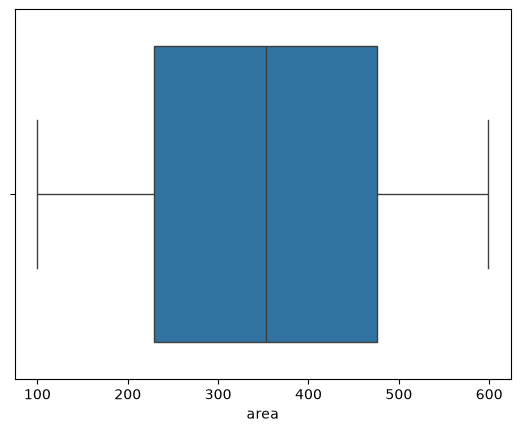

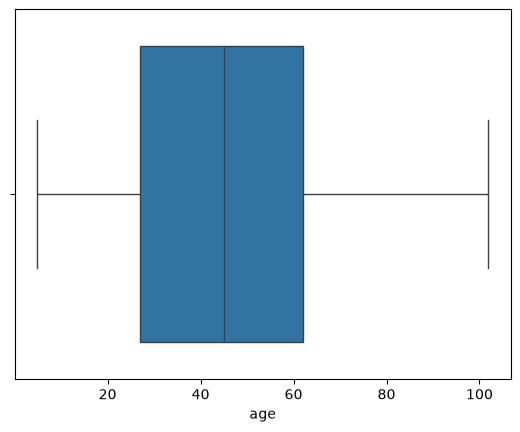

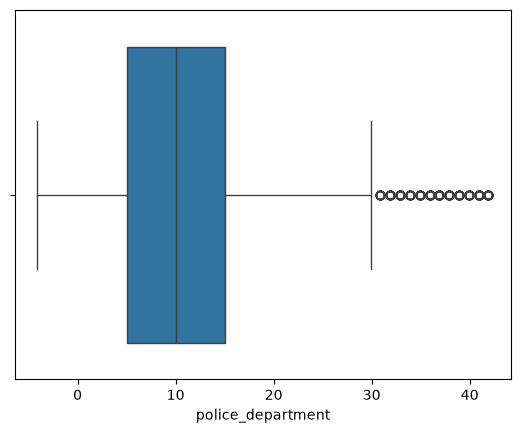

In [12]:
for i in df.select_dtypes(include = ["number",'float']).columns:
    sns.boxplot(data=df,x=i)
    plt.show()

we can ignore the fact that police department has outliers because we are not supposed to treat it as a numerical value anyways

In [13]:
df['police_department'].nunique()

57

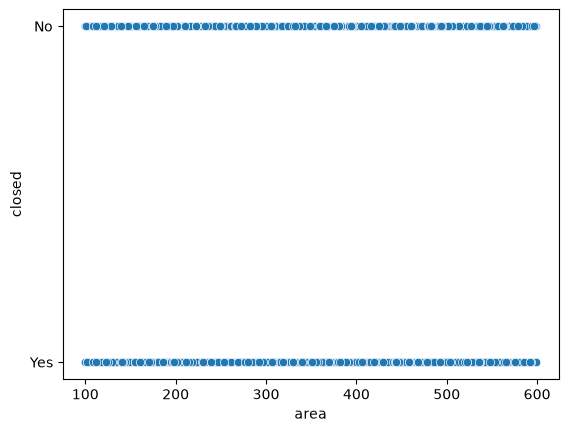

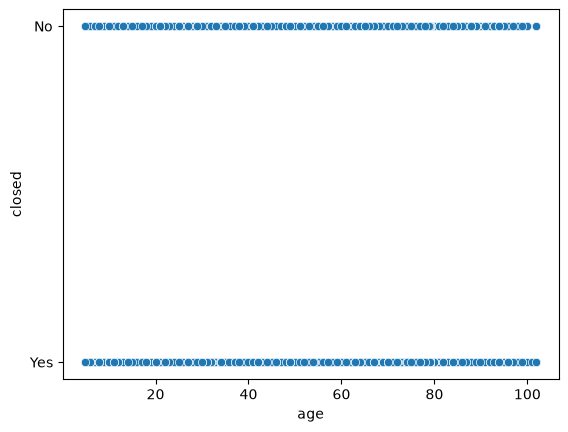

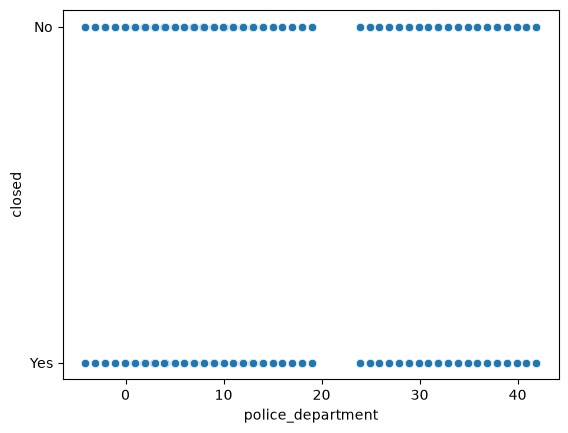

In [14]:
for i in ['area', 'age', 'police_department']:
    sns.scatterplot(data=df,x=i,y='closed')
    plt.show()

In [15]:
df.select_dtypes(include='number').columns


Index(['area', 'age', 'police_department'], dtype='str')

the fact that weapon data is null means that the weapon of crime is missing, this is actually useful data for us so instead of all null values we can put "missing"





In [16]:
df = df.fillna("Missing")

let us see if sex is a useful feature


In [17]:
df[df["closed"] == "Yes"]["sex"].value_counts()

sex
F    6268
M    3736
X    1249
Name: count, dtype: int64

In [18]:
df.groupby("sex")["closed"].value_counts(normalize=True) * 100


sex  closed
F    No        50.019935
     Yes       49.980065
M    No        50.140131
     Yes       49.859869
X    Yes       50.875764
     No        49.124236
Name: proportion, dtype: float64

sex doesnt seem like a useful feature 




In [19]:
df = df.drop('sex',axis=1)

In [20]:
df

,case_filed,city,area,crime_description,age,weapon,domain,police_department,closed
0,04-04-2022 18:00,Mumbai,307,VEHICLE - STOLEN,63.0,Poison,Violent Crime,12.0,No
1,07-27-2021 10:00,Surat,504,ROBBERY,57.0,Explosives,Violent Crime,3.0,No
2,06-16-2023 23:00,Thane,493,ASSAULT,33.0,Firearm,Violent Crime,18.0,No
3,07-29-2020 03:00,Ahmedabad,169,PUBLIC INTOXICATION,76.0,Knife,Other Crime,3.0,No
4,12-29-2023 16:00,Mumbai,133,PUBLIC INTOXICATION,13.0,Missing,Other Crime,13.0,No
...,...,...,...,...,...,...,...,...,...
22484,11-14-2020 07:00,Pune,121,SEXUAL ASSAULT,15.0,Explosives,Violent Crime,5.0,No
22485,06-01-2020 10:00,Delhi,112,DOMESTIC VIOLENCE,11.0,Other,Violent Crime,2.0,Yes
22486,03-19-2021 21:00,Jaipur,170,FRAUD,38.0,Explosives,Other Crime,9.0,Yes
22487,12-08-2020 20:00,Chennai,189,ASSAULT,13.0,Knife,Violent Crime,3.0,No


now lets encode all the categorical data

In [21]:
df = pd.get_dummies(data=df,columns=["city","area","crime_description","weapon","domain","police_department"],dtype=float,drop_first=True)

In [22]:
df["case_filed"] = pd.to_datetime(df["case_filed"])
df

,case_filed,age,closed,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,...,police_department_32.900000000000006,police_department_33.900000000000006,police_department_34.900000000000006,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006
0,2022-04-04 18:00:00,63.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2021-07-27 10:00:00,57.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2023-06-16 23:00:00,33.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2020-07-29 03:00:00,76.0,No,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2023-12-29 16:00:00,13.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,2020-11-14 07:00:00,15.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22485,2020-06-01 10:00:00,11.0,Yes,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22486,2021-03-19 21:00:00,38.0,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22487,2020-12-08 20:00:00,13.0,No,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
df['year'] = df['case_filed'].dt.year
df['month'] = df['case_filed'].dt.month
df['day'] = df['case_filed'].dt.day
df

,case_filed,age,closed,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,2022-04-04 18:00:00,63.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022,4,4
1,2021-07-27 10:00:00,57.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2021,7,27
2,2023-06-16 23:00:00,33.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2023,6,16
3,2020-07-29 03:00:00,76.0,No,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,7,29
4,2023-12-29 16:00:00,13.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2023,12,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,2020-11-14 07:00:00,15.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,11,14
22485,2020-06-01 10:00:00,11.0,Yes,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,6,1
22486,2021-03-19 21:00:00,38.0,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2021,3,19
22487,2020-12-08 20:00:00,13.0,No,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,12,8


In [24]:
df = df.drop(columns = 'case_filed')

In [25]:
df

,age,closed,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,63.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022,4,4
1,57.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2021,7,27
2,33.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2023,6,16
3,76.0,No,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,7,29
4,13.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2023,12,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,15.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,11,14
22485,11.0,Yes,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,6,1
22486,38.0,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2021,3,19
22487,13.0,No,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2020,12,8


In [26]:
df['year']=df['year']-2000

In [27]:
df

,age,closed,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,63.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22,4,4
1,57.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,7,27
2,33.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23,6,16
3,76.0,No,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,7,29
4,13.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23,12,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,15.0,No,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,11,14
22485,11.0,Yes,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,6,1
22486,38.0,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,3,19
22487,13.0,No,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,12,8


In [28]:
print(df[df['year']<0])
print(df.shape[0])

Empty DataFrame
Columns: [age, closed, city_Ahmedabad, city_Bangalore, city_Bhopal, city_Chennai, city_Delhi, city_Faridabad, city_Ghaziabad, city_Hyderabad, city_Indore, city_Jaipur, city_Kalyan, city_Kanpur, city_Kolkata, city_Lucknow, city_Ludhiana, city_Meerut, city_Mumbai, city_Nagpur, city_Nashik, city_Patna, city_Pune, city_Rajkot, city_Srinagar, city_Surat, city_Thane, city_Varanasi, city_Vasai, city_Visakhapatnam, area_101, area_102, area_103, area_104, area_105, area_106, area_107, area_108, area_109, area_110, area_111, area_112, area_113, area_114, area_115, area_116, area_117, area_118, area_119, area_120, area_121, area_122, area_123, area_124, area_125, area_126, area_127, area_128, area_129, area_130, area_131, area_132, area_133, area_134, area_135, area_136, area_137, area_138, area_139, area_140, area_141, area_142, area_143, area_144, area_145, area_146, area_147, area_148, area_149, area_150, area_151, area_152, area_153, area_154, area_155, area_156, area_157, are

im engineering a feature which uses the year month and day combined

In [29]:
df['closed'] = df['closed'].replace({
    'No': 0,
    'Yes': 1
})
df2 = df['closed']
df = df.drop(columns = 'closed')

In [30]:
df

,age,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,city_Indore,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,63.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22,4,4
1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,7,27
2,33.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23,6,16
3,76.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,7,29
4,13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23,12,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,11,14
22485,11.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,6,1
22486,38.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,3,19
22487,13.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20,12,8


In [31]:
mean = np.mean(df,axis=0)
std = np.std(df,axis=0)
df_normalized = (df - mean)/std
df_normalized

,age,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,city_Indore,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,0.883923,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.141347,-0.654569,-1.335269
1,0.592860,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-0.607829,0.225762,1.284822
2,-0.571393,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,-0.067682,0.031735
3,1.514560,4.548252,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,0.225762,1.512656
4,-1.541604,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,1.692980,1.512656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,-1.444583,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,1.399536,-0.196099
22485,-1.638625,-0.219865,-0.310283,-0.130398,-0.258927,2.543413,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,-0.067682,-1.677020
22486,-0.328841,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-0.607829,-0.948012,0.373486
22487,-1.541604,-0.219865,-0.310283,-0.130398,3.862096,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,1.692980,-0.879601


now im engineering a feature for a combined date format so that our model wil be more accurate


In [32]:
'''for i in range(df.shape[0]):
    
    df_normalized.loc[i,'date_feature'] = (2**df_normalized.loc[i,'year'])*(3**df_normalized.loc[i,'month'])*(5**df_normalized.loc[i,'day'])
df_normalized'''

"for i in range(df.shape[0]):\n\n    df_normalized.loc[i,'date_feature'] = (2**df_normalized.loc[i,'year'])*(3**df_normalized.loc[i,'month'])*(5**df_normalized.loc[i,'day'])\ndf_normalized"

In [33]:
mean = np.mean(df,axis=0)
std = np.std(df,axis=0)
df_normalized = (df - mean)/std
df_normalized

,age,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,city_Indore,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,0.883923,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.141347,-0.654569,-1.335269
1,0.592860,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-0.607829,0.225762,1.284822
2,-0.571393,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,-0.067682,0.031735
3,1.514560,4.548252,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,0.225762,1.512656
4,-1.541604,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,1.692980,1.512656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22484,-1.444583,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,1.399536,-0.196099
22485,-1.638625,-0.219865,-0.310283,-0.130398,-0.258927,2.543413,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,-0.067682,-1.677020
22486,-0.328841,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-0.607829,-0.948012,0.373486
22487,-1.541604,-0.219865,-0.310283,-0.130398,3.862096,-0.393173,-0.092062,-0.134739,-0.28203,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,1.692980,-0.879601


In [34]:
'''df_normalized = df_normalized.drop(columns = ['year','day','month'])'''
        

"df_normalized = df_normalized.drop(columns = ['year','day','month'])"

In [35]:
x_train = df_normalized.to_numpy().astype('float')
y_train = df2.to_numpy().astype('float')

y_train

array([0., 0., 0., ..., 1., 0., 0.], shape=(22489,))

In [36]:
x_train

array([[ 0.88392289, -0.21986469, -0.31028328, ...,  0.14134699,
        -0.6545687 , -1.33526907],
       [ 0.59285966, -0.21986469, -0.31028328, ..., -0.6078287 ,
         0.22576194,  1.28482221],
       [-0.57139327, -0.21986469, -0.31028328, ...,  0.89052268,
        -0.06768161,  0.03173507],
       ...,
       [-0.32884058, -0.21986469, -0.31028328, ..., -0.6078287 ,
        -0.94801224,  0.37348611],
       [-1.54160405, -0.21986469, -0.31028328, ..., -1.35700439,
         1.69297966, -0.87960102],
       [-0.86245651, -0.21986469, -0.31028328, ...,  1.63969837,
         0.22576194, -0.08218194]], shape=(22489, 616))

finally data is ready for the model


In [37]:
def sigmoid(z):
    sigmoid = 1/(1 + np.exp(-z))
    return sigmoid

In [38]:
def prediction(x,w,b):
    prediction = sigmoid(np.dot(x,w)+b)
    return prediction

In [39]:
def compute_cost(x,y,w,b):
    m = x.shape[0]
    cost = 0.0
    for i in range(m):
        z_i = np.dot(x[i],w) + b
        f_i = sigmoid(z_i)
        cost += -y[i]*np.log(f_i) - (1-y[i])*np.log(1-f_i)
    cost = cost/m
    return cost

In [40]:
def compute_gradient(x,y,w,b):
    m = x.shape[0]
    dj_dw = np.zeros(x.shape[1])
    dj_db = 0
    z = np.dot(x,w) + b
    f = sigmoid(z)
    
    dj_dw = np.dot(f-y,x)
    dj_db = np.sum(f-y)
    dj_dw = dj_dw/m
    dj_db = dj_db/m
    return dj_dw, dj_db

In [41]:
def gradient_descent(x,y,w,b,compute_gradient,compute_cost,alpha,iterations):
    
    J_history  = []
    for n in range(iterations):
        dj_dw,dj_db = compute_gradient(x,y,w,b)
        w = w - alpha*dj_dw
        b = b - alpha*dj_db
        J_history.append(compute_cost(x,y,w,b))
    return w,b,J_history

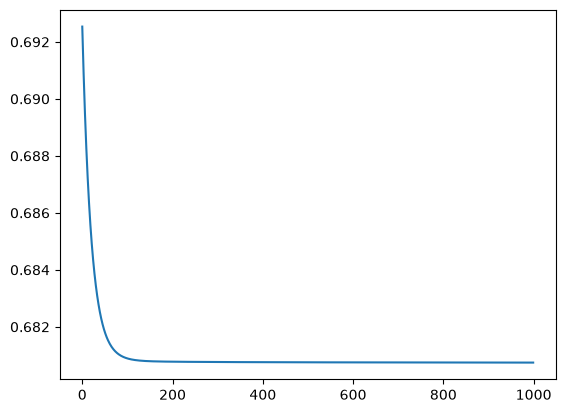

In [54]:
w_init = np.zeros(x_train.shape[1])
b_init = 0
alpha = 0.1
iterations = 1000
w,b,J_history = gradient_descent(x_train,y_train,w_init,b_init,compute_gradient,compute_cost,alpha,iterations)
plt.plot(range(iterations),J_history)
plt.show()


In [57]:
dj_dw, dj_db = compute_gradient(
    x_train, y_train, w, b
)

print("Weight gradient magnitude:",
      np.linalg.norm(dj_dw))

print("Bias gradient:",
      dj_db)

Weight gradient magnitude: 0.0003759183879081728
Bias gradient: -9.491190339755323e-09


In [56]:
print("Initial cost:", J_history[0])
print("Final cost:", J_history[-1])
print("Final bias:", b)
print("Largest absolute weight:", np.max(np.abs(w)))
print("Mean absolute weight:", np.mean(np.abs(w)))
print("Cost at iteration 100:", J_history[99])
print("Cost at iteration 500:", J_history[499])
print("Cost at iteration 1000:", J_history[999])


Initial cost: 0.6925369519116612
Final cost: 0.6807447409590417
Final bias: 0.0018067603658428963
Largest absolute weight: 0.04524980502023367
Mean absolute weight: 0.010403382391986269
Cost at iteration 100: 0.6808951998422127
Cost at iteration 500: 0.6807546207921966
Cost at iteration 1000: 0.6807447409590417


In [43]:
print(w,b)

[-2.64055593e-03 -8.89771616e-03 -1.59661052e-02 -7.24499203e-03
 -3.19133713e-03 -6.62953856e-03 -1.52437093e-04 -1.99085345e-03
  9.19591494e-03 -9.21333125e-03  2.86241076e-03 -1.62747410e-02
  6.09555468e-03 -2.26884224e-03  1.05593141e-02  2.32010571e-02
  6.80944658e-03 -2.70640826e-02  2.85254969e-03  3.70208091e-03
 -7.57468216e-03 -1.66294096e-02  5.97713621e-03 -1.30269635e-02
  1.77270287e-03  4.41629909e-05 -9.27845448e-03  5.25308648e-03
 -5.60636903e-03 -2.08420516e-02  3.46645853e-02 -1.70126162e-03
 -5.11926442e-03  1.47799332e-03  2.56410736e-02 -6.97957606e-03
 -2.60883035e-02 -1.28745813e-02  2.40624040e-02  3.45426889e-02
  1.04630552e-02  6.70694791e-03  4.62668661e-03  1.80021689e-02
  1.04673491e-02  1.45557081e-02  1.25579013e-02 -5.35316717e-03
 -5.12238856e-03 -1.10710015e-03 -1.03062678e-02 -6.30997050e-04
  1.76055598e-03 -2.95733424e-03 -5.29899835e-03  9.37344387e-03
  2.58858901e-02  1.12279538e-02  2.23911155e-02 -9.28998647e-03
 -1.23589098e-02  6.12418

In [44]:
#lets test it 
df_test = pd.read_csv("crime_test.csv")
df_test = df_test.drop(columns = ['Num','Unnamed: 0','sex'])
df_test = df_test.fillna("Missing")
df_test = pd.get_dummies(data=df_test,columns=["city","area","crime_description","weapon","domain","police_department"],dtype=float,drop_first=True)
df_test["case_filed"] = pd.to_datetime(df_test["case_filed"])
df_test['year'] = df_test['case_filed'].dt.year
df_test['month'] = df_test['case_filed'].dt.month
df_test['day'] = df_test['case_filed'].dt.day
df_test = df_test.drop(columns = 'case_filed')
df_test['year']=df_test['year']-2000
df_test['closed'] = df_test['closed'].replace({
    'No': 0,
    'Yes': 1
})
df2_test = df_test['closed']
df_test = df_test.drop(columns = 'closed')

df_normalized_t = (df_test - mean)/std
df_normalized_t
'''for i in range(df_test.shape[0]):
    
    df_normalized_t.loc[i,'date_feature'] = (2**df_normalized_t.loc[i,'year'])*(3**df_normalized_t.loc[i,'month'])*(5**df_normalized_t.loc[i,'day'])
'''
df_normalized_t

df_normalized_t = (df_test - mean)/std
df_normalized_t

,age,city_Ahmedabad,city_Bangalore,city_Bhopal,city_Chennai,city_Delhi,city_Faridabad,city_Ghaziabad,city_Hyderabad,city_Indore,...,police_department_35.900000000000006,police_department_36.900000000000006,police_department_37.900000000000006,police_department_38.900000000000006,police_department_39.900000000000006,police_department_40.900000000000006,police_department_41.900000000000006,year,month,day
0,0.592860,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,0.519205,1.512656
1,0.204775,4.548252,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,1.639698,-0.067682,0.145652
2,-0.183309,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,1.692980,-0.651767
3,-1.444583,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,3.545718,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,-0.361125,0.601320
4,-0.134798,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,3.545718,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.141347,-0.361125,-0.537850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9634,-0.862457,-0.219865,-0.310283,-0.130398,3.862096,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-1.357004,0.225762,0.943071
9635,-0.377351,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,0.519205,0.829154
9636,-1.396072,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,-0.607829,0.812649,-1.449186
9637,1.417539,-0.219865,-0.310283,-0.130398,-0.258927,-0.393173,-0.092062,-0.134739,-0.282030,-0.136946,...,-0.038912,-0.045273,-0.041141,-0.037153,-0.034021,-0.043256,-0.039481,0.890523,-0.361125,-1.335269


In [49]:
x_test = df_normalized_t.to_numpy().astype('float')
y_test = df2_test.to_numpy().astype('float')
print(x_test.dtype)

prediction = sigmoid(np.dot(x_test,w) + b)
print(prediction.shape)
for i in range(prediction.shape[0]):
    if prediction[i] > 0.5:
        prediction[i] = 1
    else:
        prediction[i] = 0
prediction


float64
(9639,)


array([1., 0., 0., ..., 1., 1., 1.], shape=(9639,))

In [50]:
accuracy = np.mean(prediction == y_test) * 100
print("Accuracy:", accuracy, "%")

Accuracy: 49.299719887955185 %


In [51]:
#lets check if its overfitting
pred2 = sigmoid(np.dot(x_train,w) + b)
for i in range(pred2.shape[0]):
    if pred2[i] > 0.5:
        pred2[i] = 1
    else:
        pred2[i] = 0
accuracy_1 = np.mean(pred2==y_train)*100
print(accuracy_1)
print("Training prediction counts:")
print("No:", np.sum(pred2 == 0))
print("Yes:", np.sum(pred2 == 1))

print("Actual training counts:")
print("No:", np.sum(y_train == 0))
print("Yes:", np.sum(y_train == 1))

55.90733247365378
Training prediction counts:
No: 11424
Yes: 11065
Actual training counts:
No: 11236
Yes: 11253
